# B. Student: antrenare, evaluare și export pentru NPU (Colab, GPU)

Fazele 5–8 din plan. Necesită datele din notebook-ul A.

**Runtime:** *Runtime → Change runtime type* → **T4 GPU** și **Runtime version: 2026.07** (Python 3.12). Runtime-ul implicit 2026.10 are Python 3.13, pentru care TensorFlow 2.19.0 nu există.

**Versiunea TensorFlow trebuie să fie 2.19.0**, ca TFLite 2.19.0 de pe placă. După instalare, Colab cere *Restart session*: acceptă, apoi sari peste celula de instalare și rulează de la celula 2.

In [1]:
import sys
print("Python", sys.version.split()[0])
assert sys.version_info[:2] <= (3, 12), (
    "TensorFlow 2.19.0 nu există pentru Python 3.13. Alege Runtime -> Change runtime type -> "
    "Runtime version: 2026.07 (Python 3.12), apoi rulează din nou.")
!pip -q install tensorflow==2.19.0 ai-edge-litert

Python 3.12.13
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.8/21.8 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 44.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.19.0 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.19.0 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.19.0 which is incompatible.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.environ["ECA_ROOT"] = "/content/drive/MyDrive/ECA_depth"   # date și rezultate (persistente)
os.environ["ECA_RAW"] = "/content/kitti_raw"                  # KITTI brut (disc local, temporar)
os.environ["UNIMATCH_DIR"] = "/content/unimatch"
# os.environ["ECA_DEBUG"] = "1"   # decomentează pentru un test rapid pe 2 secvențe mici

COD = "/content/drive/MyDrive/ECA_depth/cod"   # aici ai urcat folderul cod/
%cd {COD}
!nvidia-smi --query-gpu=name,memory.total --format=csv

import tensorflow as tf; print("TensorFlow", tf.__version__)
assert tf.__version__.startswith("2.19"), "Restart session și rulează din nou"

Mounted at /content/drive
/content/drive/MyDrive/ECA_depth/cod
name, memory.total [MiB]
Tesla T4, 15360 MiB
TensorFlow 2.19.0


In [3]:
from pathlib import Path
import importlib
import config as C

importlib.reload(C)

proc = Path(C.PROC_DIR)
missing = []

if not (proc / "meta.json").is_file():
    missing.append(str(proc / "meta.json"))

for split, drives in C.SPLITS.items():
    for drive in drives:
        name = C.drive_name(drive)

        for filename in (
            name + ".npz",
            name + C.TEACHER_SUFFIX,
        ):
            path = proc / filename
            if not path.is_file():
                missing.append(f"[{split}] {path}")

print("Folder de date:", proc)
print("Teacher:", C.TEACHER_ID)

if missing:
    print("\nLipsesc următoarele fișiere:")
    for path in missing:
        print(" -", path)
    print("\nContinuă notebook-ul A înainte de antrenare.")
else:
    print("\nOK: toate fișierele necesare există.")

Folder de date: /content/drive/MyDrive/ECA_depth/proc
Teacher: gmstereo_kitti15_04487ebf

OK: toate fișierele necesare există.


## 1. Test rapid al pierderilor (30 s)
Verifică direcția reconstrucției stereo și că gradientul ajunge la rețea. Trebuie să vezi `TOATE TESTELE AU TRECUT`.

In [4]:
!python teste/test_pierderi.py

2026-11-03 14:23:39.566482: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793715819.603054    1737 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793715819.615042    1737 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793715819.642665    1737 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793715819.642719    1737 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793715819.642727    1737 computation_placer.cc:177] computation placer alr

## 2. Baseline – fără teacher (faza 5)
Aceeași arhitectură, aceleași date, aceeași inițializare; doar pierderea fotometrică + netezime.

In [5]:
!python 03_antrenare.py --mod baseline

2026-11-03 14:24:10.344143: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793715850.383289    2016 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793715850.396858    2016 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793715850.426510    2016 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793715850.426566    2016 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793715850.426577    2016 computation_placer.cc:177] computation placer alr

## 3. Student ghidat – cu teacher (faza 6)

In [6]:
!python 03_antrenare.py --mod ghidat

2026-11-03 14:30:39.627456: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793716239.650654    3795 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793716239.658907    3795 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793716239.682997    3795 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716239.683037    3795 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716239.683043    3795 computation_placer.cc:177] computation placer alr

## 4. Curbele de antrenare

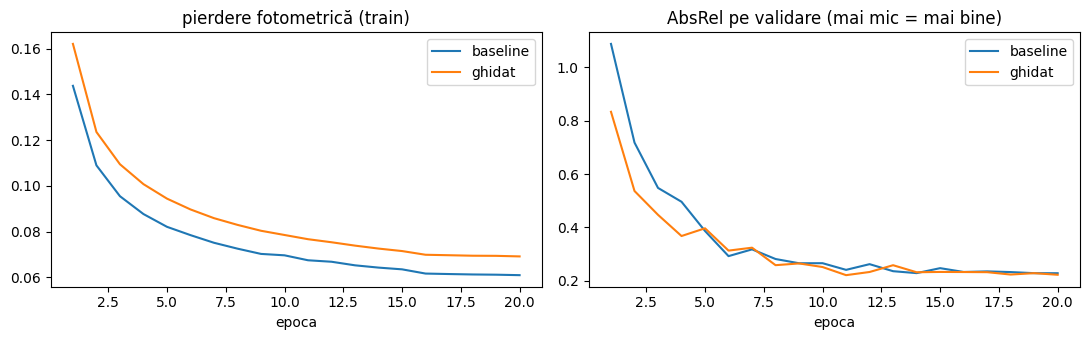

In [7]:
import pandas as pd, matplotlib.pyplot as plt, config as C
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for mod in ["baseline", "ghidat"]:
    log = pd.read_csv(f"{C.RUNS_DIR}/{mod}/log.csv")
    ax[0].plot(log.epoca, log.photo, label=mod); ax[1].plot(log.epoca, log.val_abs_rel, label=mod)
ax[0].set_title("pierdere fotometrică (train)"); ax[1].set_title("AbsRel pe validare (mai mic = mai bine)")
for a in ax: a.legend(); a.set_xlabel("epoca")
plt.tight_layout()

## 5. Export pentru NPU (faza 8)
TFLite float, int8 per-canal și int8 per-tensor, calibrate pe 200 de imagini reale de antrenament.

In [8]:
!python 05_export.py --nume baseline
!python 05_export.py --nume ghidat

2026-11-03 14:36:31.291450: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793716591.312881    5420 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793716591.319774    5420 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793716591.336641    5420 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716591.336682    5420 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716591.336687    5420 computation_placer.cc:177] computation placer alr

## 6. Evaluare finală pe TEST (faza 7)
O singură dată, la final. Include efectul cuantizării int8.

In [9]:
!python 04_evaluare.py --modele baseline ghidat --tflite \
    student_baseline_float.tflite student_baseline_int8.tflite student_baseline_int8_pt.tflite \
    student_ghidat_float.tflite student_ghidat_int8.tflite student_ghidat_int8_pt.tflite

2026-11-03 14:39:34.646535: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793716774.670043    6412 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793716774.677556    6412 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793716774.695358    6412 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716774.695422    6412 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716774.695428    6412 computation_placer.cc:177] computation placer alr

In [ ]:
from IPython.display import Markdown, Image, display
display(Markdown(open(f"{C.ROOT}/rezultate_test.md").read()))
import glob
for p in sorted(glob.glob(f"{C.ROOT}/figuri/test_*.png"))[:3]: display(Image(p))

## 7. Pachetul pentru placă
Conține modelele int8, scripturile din `placa/`, fișierele de referință și imaginile de demo. Descarcă `pachet_placa.zip` și dă-l colegei (sau copiază-l direct cu `scp`).

In [11]:
!python 06_imagini_demo.py --n 30
!cp placa/ruleaza_depth.py placa/benchmark.sh {C.EXPORT_DIR}/
%cd {C.EXPORT_DIR}
!zip -qr /content/pachet_placa.zip *int8*.tflite ref_*.npy ruleaza_depth.py benchmark.sh demo_imagini
%cd {COD}
from google.colab import files; files.download("/content/pachet_placa.zip")

2026-11-03 14:42:01.331114: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793716921.365455    7102 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793716921.376373    7102 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793716921.403919    7102 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716921.403972    7102 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793716921.403977    7102 computation_placer.cc:177] computation placer alr

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
%cd /content/drive/MyDrive/ECA_depth/cod

from pathlib import Path
import tflite_runner
from student_model import decode_disparity

MODEL = Path(
    "/content/drive/MyDrive/ECA_depth/export/"
    "student_ghidat_int8.tflite"
)

if not MODEL.is_file():
    raise FileNotFoundError(f"Nu găsesc modelul: {MODEL}")

interpreter = tflite_runner.make_interpreter(str(MODEL))
print("Model încărcat:", MODEL.name)

/content/drive/MyDrive/ECA_depth/cod
Model încărcat: student_ghidat_int8.tflite


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saving picture1.png to picture1 (1).png


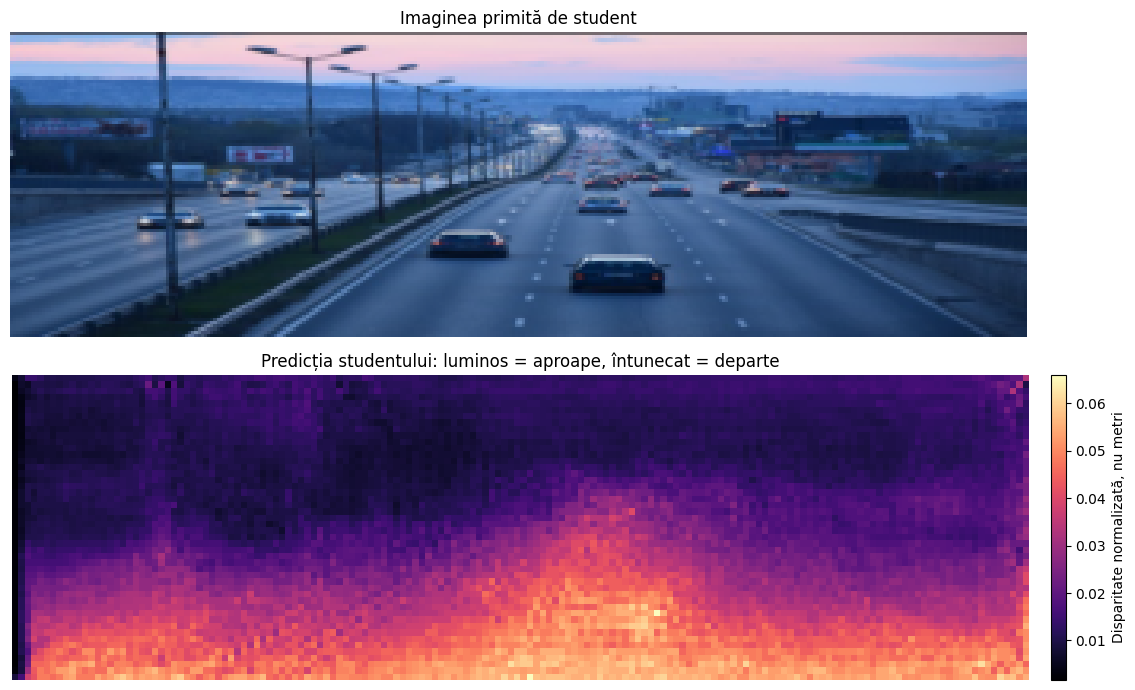

Imagine testată: picture1 (1).png
Forma intrării: (1, 96, 320, 3)
Forma predicției: (48, 160)


In [14]:
from google.colab import files
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

# 1. Alegi imaginea de pe calculator.
uploaded = files.upload()

if not uploaded:
    raise ValueError("Nu ai selectat nicio imagine.")

filename = next(iter(uploaded))
original = Image.open(
    io.BytesIO(uploaded[filename])
).convert("RGB")

# 2. Exact aceeași pregătire ca la antrenare:
# RGB, 320×96, valori în [0, 255].
resized = original.resize(
    (C.IMG_W, C.IMG_H),
    Image.Resampling.BILINEAR
)

x = np.asarray(resized, dtype=np.float32)[None, ...]

# 3. Inferență.
# Funcția aplică automat cuantizarea intrării și
# de-cuantizarea ieșirii modelului int8.
output = tflite_runner.run(interpreter, x)

s = output[0, ..., 0]
q = decode_disparity(s)

# 4. Afișare.
# q este disparitatea normalizată:
# valori mai mari = obiecte estimate mai aproape.
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].imshow(resized)
axes[0].set_title("Imaginea primită de student")
axes[0].axis("off")

heatmap = axes[1].imshow(
    q,
    cmap="magma",
    interpolation="nearest"
)
axes[1].set_title(
    "Predicția studentului: luminos = aproape, întunecat = departe"
)
axes[1].axis("off")

fig.colorbar(
    heatmap,
    ax=axes[1],
    label="Disparitate normalizată, nu metri",
    fraction=0.025,
    pad=0.02
)

plt.tight_layout()
plt.show()

# 5. Salvăm vizualizarea și predicția numerică.
fig.savefig(
    "/content/test_student.png",
    dpi=150,
    bbox_inches="tight"
)
np.save("/content/predictie_q.npy", q)

print("Imagine testată:", filename)
print("Forma intrării:", x.shape)
print("Forma predicției:", q.shape)